# Domino's Pizza Consulting (SI 485): Michigan Census Data Pipeline

**Data:** U.S. Census Bureau, American Community Survey (ACS) 5-Year Estimates, 2024 (survey responses collected 2020 through 2024)

This notebook is a **data pipeline**. Each stage feeds the next one:

```
0. SETTINGS  ->  1. EXTRACT  ->  2. TRANSFORM  ->  3. ANALYZE  ->  4. OUTPUT
 (what to       (pull from      (clean, %MoE,     (summaries,     (heat maps,
  pull)          Census API)     apply MoE rules)  data loss)      saved files)
```

**To run it for a different state or add a variable, you only change the Settings cell.** Everything after it runs the same way.


In [34]:
import requests                    # lets us download data from the internet
import pandas as pd                # lets us work with data in tables
import plotly.express as px        # draws the interactive county maps
import geopandas as gpd            # reads map shapes (for the tract maps)
import matplotlib.pyplot as plt    # draws the tract maps
from matplotlib.patches import Patch   # lets us build a color key (legend) by hand

## 0. Settings (the only cell you need to change)

**To pull an additional column:** add one line to `VARIABLES` with the Census code and a short name. The pipeline pulls both its estimate (E) and its margin of error (M) automatically. To also draw it as a heat map, add it to `MAP_COLORS`.

Look up codes at https://api.census.gov/data/2024/acs/acs5/variables.html

In [35]:
# are we running in Google Colab? (True in Colab, False in Jupyter on a computer)
API_KEY = "974ae110b0c489d1473208c73e3fa1e7095704a2"                       # on a computer: paste your key here

# which state and which year of data
STATE_CODE = "26"            # Michigan's 2-digit state code (FIPS code)
STATE_NAME = "Michigan"
YEAR = "2024"                # the 2024 ACS 5-year data (covers 2020-2024; newest available)

# the Census variables to pull: "code": "short name"
# to pull another column, add a line here (leave "population" in, the pipeline uses it)
VARIABLES = {
    "B19013_001": "median_income",   # median household income (dollars)
    "B01002_001": "median_age",      # median age (years)
    "B01003_001": "population",      # total population (people)
}

# MARGIN OF ERROR RULES, using %MoE = MoE / Estimate x 100
# counties: reject a value if its %MoE is above this number
COUNTY_REJECT_CUTOFF = {"median_income": 10, "median_age": 10}

# tracts: flag "caution" above the first number, "rejected" above the second
TRACT_CAUTION_CUTOFF = {"median_income": 30, "median_age": 15}
TRACT_REJECT_CUTOFF = {"median_income": 66, "median_age": 20}

# which variables to draw as heat maps, and the color for each
MAP_COLORS = {"median_income": "Greens", "median_age": "Blues", "population": "Purples"}

# the area to show close up on the tract maps
CLOSE_UP_NAME = "Detroit"
CLOSE_UP_COUNTIES = ["163"]
# set to True to save the data (CSV) and county maps (HTML) on your computer
SAVE_FILES = False

## 1. Extract: pull the data from the Census API

One function does the pulling for **any** geography (counties or tracts). For every variable in `VARIABLES`, it asks for:
- the **estimate** (code ending in `E`)
- the **margin of error** (code ending in `M`). Census gives this as a **value** in the same units as the estimate (dollars, years, people), at the **90% confidence level**.

In [36]:
def pull_census(geography):
    # start the list of columns with the place name
    columns = ["NAME"]

    # add the estimate (E) and margin of error (M) for every variable in our settings
    for census_code in VARIABLES:
        columns.append(census_code + "E")
        columns.append(census_code + "M")

    # what we are asking the Census for
    params = {
        "get": ",".join(columns),          # the columns, separated by commas
        "for": geography,                  # e.g. "county:*" or "tract:*"
        "in": "state:" + STATE_CODE,       # only our state
        "key": API_KEY                     # our key
    }

    # the web address for the ACS 5-year data in our chosen year
    url = "https://api.census.gov/data/" + YEAR + "/acs/acs5"

    # send the request and turn the answer into a table (the first row is the column names)
    data = requests.get(url, params=params).json()
    table = pd.DataFrame(data[1:], columns=data[0])

    # rename the codes to short names, e.g. B19013_001E -> median_income, B19013_001M -> median_income_moe
    for census_code, name in VARIABLES.items():
        table = table.rename(columns={census_code + "E": name, census_code + "M": name + "_moe"})

    return table


# pull every county and every census tract in the state
counties = pull_census("county:*")
tracts = pull_census("tract:*")

print("Counties pulled:", len(counties))
print("Tracts pulled:", len(tracts))
tracts.head()

Counties pulled: 83
Tracts pulled: 3017


,NAME,median_income,median_income_moe,median_age,median_age_moe,population,population_moe,state,county,tract
0,Census Tract 1; Alcona County; Michigan,70326,4726,63.6,1.1,1837,167,26,001,000100
1,Census Tract 9701; Alcona County; Michigan,52781,3082,59.6,1.8,2446,161,26,001,970100
2,Census Tract 9704; Alcona County; Michigan,57350,5640,56.7,2.9,2819,212,26,001,970400
3,Census Tract 9705; Alcona County; Michigan,46759,5790,60.3,2.2,1974,170,26,001,970500
4,Census Tract 9706; Alcona County; Michigan,54274,8193,58.6,5.0,1321,163,26,001,970600


In [37]:
# download the county shapes (outline of every U.S. county) for the interactive county maps
county_shapes = requests.get("https://raw.githubusercontent.com/plotly/datasets/master/geojson-counties-fips.json").json()

# keep only our state's counties (their codes start with our state code) so the file stays small
state_shapes = []
for shape in county_shapes["features"]:
    if shape["id"].startswith(STATE_CODE):
        state_shapes.append(shape)
county_shapes["features"] = state_shapes

# download the census tract shapes for our state from the Census Bureau
tract_shapes = gpd.read_file("https://www2.census.gov/geo/tiger/GENZ" + YEAR + "/shp/cb_" + YEAR + "_" + STATE_CODE + "_tract_500k.zip")

print("County shapes:", len(county_shapes["features"]))
print("Tract shapes:", len(tract_shapes))

County shapes: 83
Tract shapes: 2971


## 2. Transform: clean the data and apply the margin of error rules

For every variable, the cleaning step:
1. Turns the text into numbers.
2. Treats **Census special codes** as missing. These are big negative numbers:
   - `-666666666` = no estimate (usually nobody lives there, like a park or airport)
   - `-222222222` = no MoE because there's no estimate
   - `-333333333` = the median is in the top or bottom bracket (income shows as `250001`, meaning "$250,000 or more"). **We keep the estimate**; only the MoE is unknown.
   - `-555555555` = the number is fixed by Census, so there's no sampling error
3. Works out **%MoE = MoE / Estimate x 100**.
4. Gives each value a **status**: `ok`, `caution`, `rejected`, `no data`, or `no MoE (kept)`.
5. Makes a `_final` column that only holds the values we trust. Rejected values become blank (they show up gray on the maps).

In [38]:
def get_status(estimate, pct_moe, caution, reject):
    if pd.isna(estimate):                           # Census gave no estimate
        return "no data"
    if pd.isna(pct_moe):                            # there is an estimate but no MoE (special code)
        return "no MoE (kept)"
    if reject is not None and pct_moe > reject:     # too uncertain: throw it out
        return "rejected"
    if caution is not None and pct_moe > caution:   # usable, but be careful
        return "caution"
    return "ok"


def clean(table, caution_cutoffs, reject_cutoffs):
    for name in VARIABLES.values():
        moe = name + "_moe"

        # turn text into numbers
        table[name] = pd.to_numeric(table[name])
        table[moe] = pd.to_numeric(table[moe])

        # special codes are negative numbers: keep only values of 0 or more (the rest become blank)
        table[name] = table[name].where(table[name] >= 0)
        table[moe] = table[moe].where(table[moe] >= 0)

        # %MoE = MoE / Estimate x 100 (only where the estimate is above 0, so we never divide by 0)
        table[name + "_pct_moe"] = (table[moe] / table[name] * 100).where(table[name] > 0)

        # give every row a status using our rules (variables with no rule get None = no cutoff)
        caution = caution_cutoffs.get(name)
        reject = reject_cutoffs.get(name)
        statuses = []
        for estimate, pct in zip(table[name], table[name + "_pct_moe"]):
            statuses.append(get_status(estimate, pct, caution, reject))
        table[name + "_status"] = statuses

        # the final value we use: blank out anything rejected
        table[name + "_final"] = table[name].where(table[name + "_status"] != "rejected")

    return table


# clean both tables (counties have no "caution" level, so we pass an empty {})
counties = clean(counties, {}, COUNTY_REJECT_CUTOFF)
tracts = clean(tracts, TRACT_CAUTION_CUTOFF, TRACT_REJECT_CUTOFF)

# make the ID codes the maps use to match rows to shapes
counties["fips"] = counties["state"] + counties["county"]                     # 5 digits: state + county
tracts["GEOID"] = tracts["state"] + tracts["county"] + tracts["tract"]        # 11 digits: state + county + tract

# remove the state name from the place names so they look cleaner
counties["NAME"] = counties["NAME"].str.replace(", " + STATE_NAME, "")

counties.head()

,NAME,median_income,median_income_moe,median_age,median_age_moe,population,population_moe,state,county,median_income_pct_moe,median_income_status,median_income_final,median_age_pct_moe,median_age_status,median_age_final,population_pct_moe,population_status,population_final,fips
0,Alcona County,54993,1572,60.0,0.4,10397,NaN,26,001,2.858546,ok,54993.0,0.666667,ok,60.0,NaN,no MoE (kept),10397,26001
1,Alger County,61286,1930,49.1,0.5,8762,NaN,26,003,3.149169,ok,61286.0,1.018330,ok,49.1,NaN,no MoE (kept),8762,26003
2,Allegan County,83283,2480,41.0,0.4,121456,NaN,26,005,2.977799,ok,83283.0,0.975610,ok,41.0,NaN,no MoE (kept),121456,26005
3,Alpena County,53950,2679,47.8,0.4,28880,NaN,26,007,4.965709,ok,53950.0,0.836820,ok,47.8,NaN,no MoE (kept),28880,26007
4,Antrim County,72054,2793,51.8,0.3,24127,NaN,26,009,3.876259,ok,72054.0,0.579151,ok,51.8,NaN,no MoE (kept),24127,26009


## 3. Analyze

### 3a. County summary
The average and middle value **across counties** (each county counts once, no matter its size), plus how big the margins of error are.

In [39]:
summary_rows = []
for name in MAP_COLORS:                       # the variables we map (income and age)
    summary_rows.append({
        "variable": name,
        "average across counties": round(counties[name].mean(), 1),
        "middle county (median)": round(counties[name].median(), 1),
        "average MoE (value)": round(counties[name + "_moe"].mean(), 2),      # blank = Census gives no MoE
        "average %MoE": round(counties[name + "_pct_moe"].mean(), 1),
        "largest %MoE": round(counties[name + "_pct_moe"].max(), 1),
        "counties rejected": (counties[name + "_status"] == "rejected").sum(),
    })

pd.DataFrame(summary_rows)

,variable,average across counties,middle county (median),average MoE (value),average %MoE,largest %MoE,counties rejected
0,median_income,66133.1,63724.0,2764.92,4.3,11.3,3
1,median_age,45.3,44.2,0.39,0.8,3.9,0
2,population,121418.8,37693.0,NaN,NaN,NaN,0


In [40]:
# the top 5 and bottom 5 counties for each variable, with their margins of error
for name in MAP_COLORS:
    columns_to_show = ["NAME", name, name + "_moe", name + "_pct_moe"]
    print("HIGHEST", name)
    print(counties.sort_values(name, ascending=False)[columns_to_show].head(5).round(1).to_string(index=False))
    print()
    print("LOWEST", name)
    print(counties.sort_values(name)[columns_to_show].head(5).round(1).to_string(index=False))
    print()

HIGHEST median_income
             NAME  median_income  median_income_moe  median_income_pct_moe
Livingston County         103039               1720                    1.7
  Leelanau County          99422               6699                    6.7
   Oakland County          97760               1268                    1.3
    Ottawa County          90502               1860                    2.1
 Washtenaw County          89180               2487                    2.8

LOWEST median_income
              NAME  median_income  median_income_moe  median_income_pct_moe
      Clare County          49384               2661                    5.4
     Oscoda County          49515               3496                    7.1
Montmorency County          49756               3273                    6.6
      Iosco County          50066               2086                    4.2
       Lake County          50805               2404                    4.7

HIGHEST median_age
              NAME  median_age

### 3b. Are two counties really different? (comparison rule)
Two estimates are only **significantly different** if the gap between them is bigger than their combined MoE:
**|A - B| > square root of (MoE_A squared + MoE_B squared)**

Here we test each county against the next one in the ranking.

In [41]:
for name in MAP_COLORS:
    ranked = counties.sort_values(name, ascending=False).reset_index()   # highest first
    print("Top 5 for", name)
    for i in range(5):
        a = ranked.loc[i]           # this county
        b = ranked.loc[i + 1]       # the next county down
        gap = a[name] - b[name]
        combined_moe = (a[name + "_moe"] ** 2 + b[name + "_moe"] ** 2) ** 0.5
        if pd.isna(combined_moe):                   # Census gave no MoE (e.g. county population is a fixed count)
            verdict = "no MoE, so the count is treated as exact"
        elif gap > combined_moe:
            verdict = "really higher"
        else:
            verdict = "statistically TIED"
        print("  " + a["NAME"] + " vs " + b["NAME"] + ": gap " + str(round(gap, 1)) + ", combined MoE " + str(round(combined_moe, 1)) + " -> " + verdict)
    print()

Top 5 for median_income
  Livingston County vs Leelanau County: gap 3617, combined MoE 6916.3 -> statistically TIED
  Leelanau County vs Oakland County: gap 1662, combined MoE 6817.9 -> statistically TIED
  Oakland County vs Ottawa County: gap 7258, combined MoE 2251.1 -> really higher
  Ottawa County vs Washtenaw County: gap 1322, combined MoE 3105.6 -> statistically TIED
  Washtenaw County vs Clinton County: gap 970, combined MoE 4808.2 -> statistically TIED

Top 5 for median_age
  Alcona County vs Ontonagon County: gap 0.2, combined MoE 0.7 -> statistically TIED
  Ontonagon County vs Roscommon County: gap 2.1, combined MoE 0.8 -> really higher
  Roscommon County vs Keweenaw County: gap 0.6, combined MoE 2.3 -> statistically TIED
  Keweenaw County vs Montmorency County: gap 0.2, combined MoE 2.4 -> statistically TIED
  Montmorency County vs Presque Isle County: gap 0.8, combined MoE 0.9 -> statistically TIED

Top 5 for population
  Wayne County vs Oakland County: gap 492434, combined

### 3c. Tract reliability
How many tracts fall into each status with our rules?

In [42]:
# count each status for each mapped variable
status_counts = {}
for name in MAP_COLORS:
    status_counts[name] = tracts[name + "_status"].value_counts()

pd.DataFrame(status_counts).fillna(0).astype(int)

,median_income,median_age,population
caution,468,387,0
no MoE (kept),2,0,103
no data,146,109,0
ok,2355,2108,2914
rejected,46,413,0


### 3d. How much data does each %MoE cutoff throw away?
If we rejected every tract above a cutoff, what share of tracts and **people** would we lose, statewide and in the close-up area?

This matters for Domino's: if a rule throws out dense city neighborhoods more than other places, the analysis would leave out key delivery markets.

In [43]:
total_people = tracts["population"].sum()                              # everyone in the state
in_close_up = tracts["county"].isin(CLOSE_UP_COUNTIES)                 # True for tracts in the close-up area
close_up_people = tracts.loc[in_close_up, "population"].sum()          # everyone in the close-up area

loss_rows = []
for cutoff in [5, 10, 15, 20, 25, 30, 40, 50, 66]:
    row = {"%MoE cutoff": cutoff}
    for name in MAP_COLORS:
        # a tract survives if its %MoE is under the cutoff, or it has an estimate but no MoE (kept)
        survives = (tracts[name + "_pct_moe"] <= cutoff) | (tracts[name + "_status"] == "no MoE (kept)")
        row[name + ": % tracts lost"] = round(100 - survives.mean() * 100, 1)
        row[name + ": % people lost"] = round(100 - tracts.loc[survives, "population"].sum() / total_people * 100, 1)
        row[name + ": % " + CLOSE_UP_NAME + " people lost"] = round(100 - tracts.loc[survives & in_close_up, "population"].sum() / close_up_people * 100, 1)
    loss_rows.append(row)

pd.DataFrame(loss_rows)

,%MoE cutoff,median_income: % tracts lost,median_income: % people lost,median_income: % Detroit people lost,median_age: % tracts lost,median_age: % people lost,median_age: % Detroit people lost,population: % tracts lost,population: % people lost,population: % Detroit people lost
0,5,98.6,98.5,98.7,91.6,91.3,94.9,90.0,91.8,99.2
1,10,86.6,85.2,88.9,57.7,53.3,71.6,67.4,64.6,90.7
2,15,64.9,61.2,76.9,30.1,23.7,42.2,29.2,24.1,54.5
3,20,44.5,38.4,56.6,17.3,10.9,25.3,12.6,8.8,28.0
4,25,30.7,23.9,41.5,11.1,5.5,14.8,5.8,3.1,11.6
5,30,21.9,15.1,31.0,8.2,2.9,9.4,2.3,0.9,3.9
6,40,12.6,6.2,16.5,5.1,0.8,3.3,0.8,0.2,0.8
7,50,8.8,3.3,9.5,4.2,0.3,1.7,0.5,0.0,0.2
8,66,6.4,1.5,3.6,3.8,0.0,0.1,0.3,0.0,0.0


## 4. Output: heat maps

### 4a. County heat maps
Each county is colored by its value. In Jupyter you can hover over a county to see its name and value; the picture underneath shows up on GitHub.

In [44]:
county_maps = {}    # we keep the maps here so we can save them at the end

for name, color in MAP_COLORS.items():
    county_map = px.choropleth(
        counties,                            # our county table
        geojson=county_shapes,               # the county shapes
        locations="fips",                    # the column that matches each row to a shape
        color=name + "_final",               # color by the value we trust
        color_continuous_scale=color,        # light = low, dark = high
        hover_name="NAME",                   # show the county name on hover
        hover_data={name + "_moe": True, name + "_pct_moe": ":.1f"},   # also show the MoE on hover
        labels={name + "_final": name},
        title=name + " by County, " + STATE_NAME + " (ACS " + YEAR + " 5-Year)"
    )
    county_map.update_geos(fitbounds="locations", visible=False)    # zoom in on our state

    if IN_COLAB:
        county_map.show()                        # Colab shows interactive maps its own way
    else:
        # "notebook_connected" loads the map tools from the internet, which keeps this file small enough for GitHub
        county_map.show("notebook_connected")
        # also show it as a plain picture so it is visible on GitHub (needs the kaleido add-on)
        county_map.show("png", width=900, height=650)

    county_maps[name] = county_map

### 4b. Census tract heat maps
Each tract is colored by its value. **Gray tracts are rejected by our MoE rules or have no data.** The right side zooms in on the close-up area, because city tracts are too small to see on the state map.

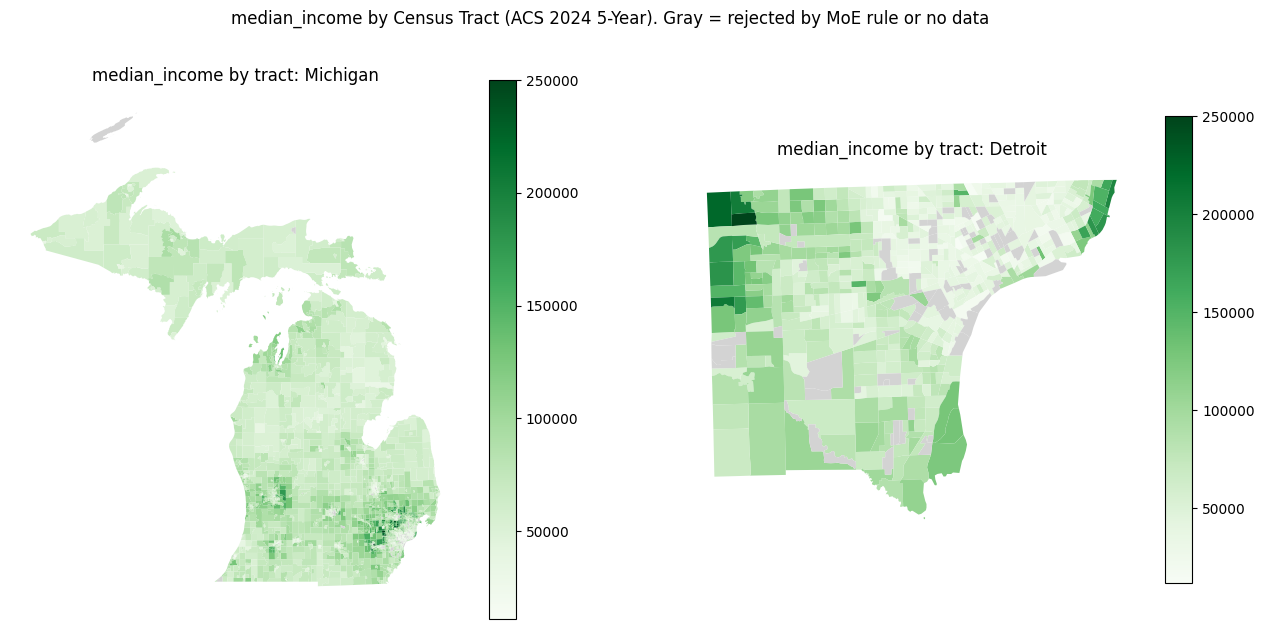

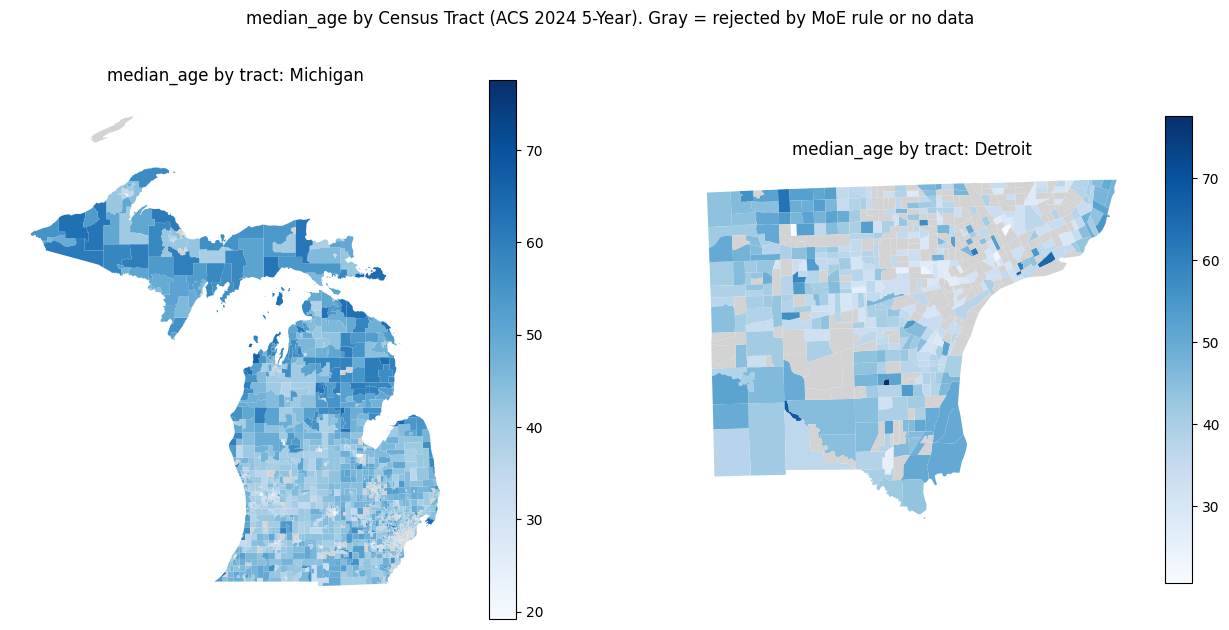

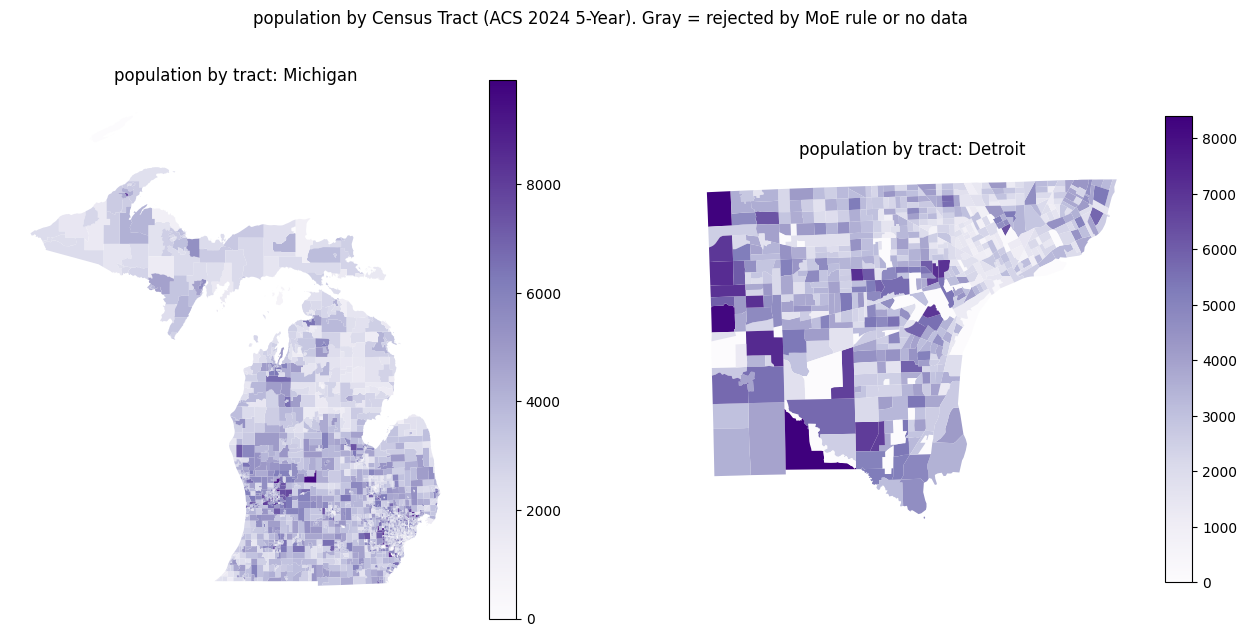

In [45]:
# attach our tract data to the tract shapes, matching on the 11-digit GEOID
tract_map_data = tract_shapes.merge(tracts, on="GEOID", how="left")
close_up = tract_map_data[tract_map_data["COUNTYFP"].isin(CLOSE_UP_COUNTIES)]   # just the close-up area

for name, color in MAP_COLORS.items():
    # two maps side by side: whole state (left) and close-up (right)
    fig, (left, right) = plt.subplots(1, 2, figsize=(16, 7))

    for ax, data, title in [(left, tract_map_data, STATE_NAME), (right, close_up, CLOSE_UP_NAME)]:
        data.plot(
            column=name + "_final",                  # color by the value we trust
            cmap=color,                              # light = low, dark = high
            legend=True,                             # show the color bar
            ax=ax,
            missing_kwds={"color": "lightgrey"},     # rejected / no data = gray
        )
        ax.set_title(name + " by tract: " + title)
        ax.axis("off")                               # hide the x/y axis numbers

    fig.suptitle(name + " by Census Tract (ACS " + YEAR + " 5-Year). Gray = rejected by MoE rule or no data")
    plt.show()

### 4c. Reliability maps
Where is the data trustworthy? Each tract is colored by its **status** from our MoE rules.

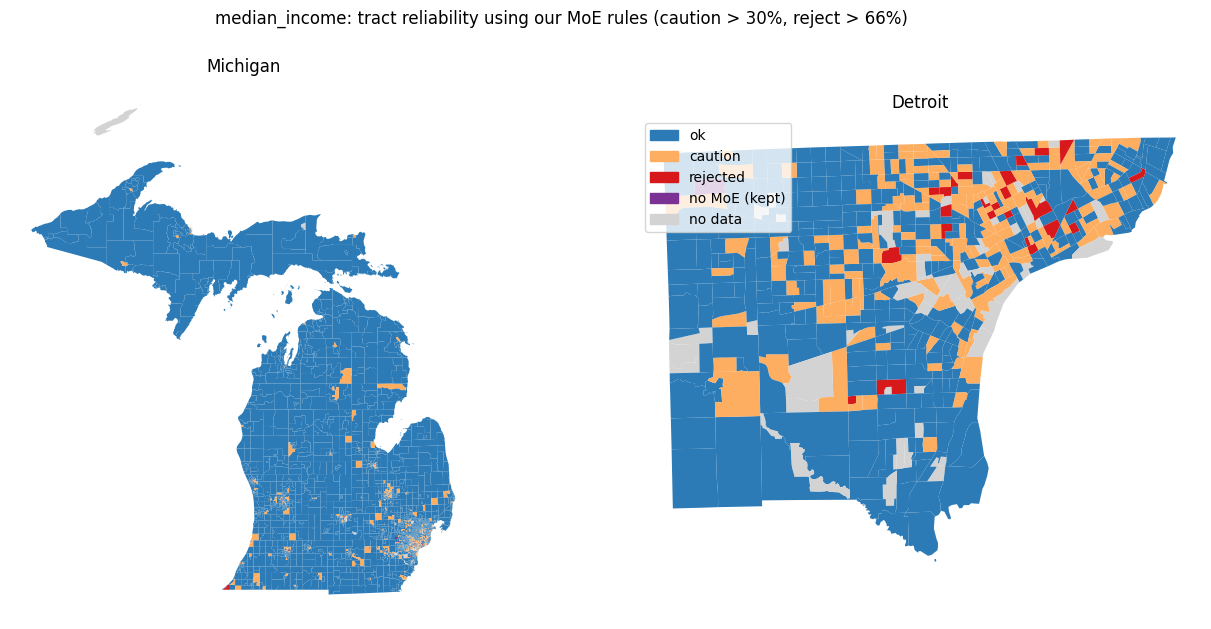

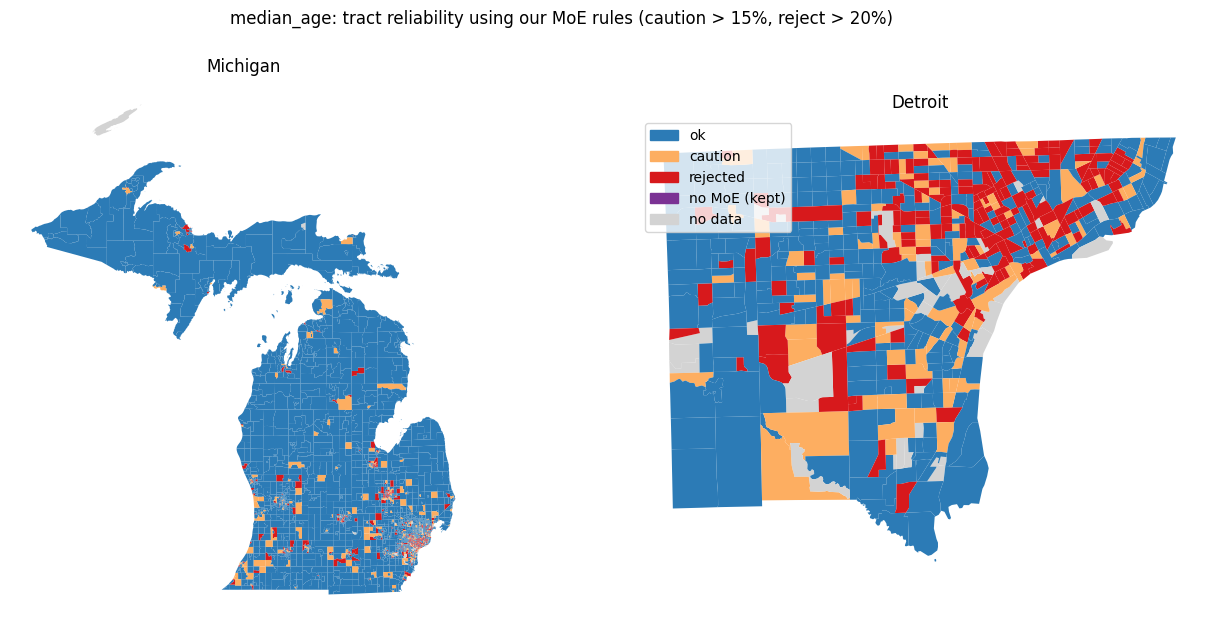

In [46]:
# one color for each status
status_colors = {
    "ok": "#2c7bb6",              # blue
    "caution": "#fdae61",         # orange
    "rejected": "#d7191c",        # red
    "no MoE (kept)": "#7b3294",   # purple (e.g. income of $250,000+)
    "no data": "lightgrey",
}

for name in MAP_COLORS:
    # skip variables that have no MoE rule in Settings (every tract would just be "ok")
    if name not in TRACT_REJECT_CUTOFF:
        continue

    # look up the color for each tract's status (tracts with no match at all are gray)
    tract_map_data["status_color"] = tract_map_data[name + "_status"].map(status_colors).fillna("lightgrey")
    close_up = tract_map_data[tract_map_data["COUNTYFP"].isin(CLOSE_UP_COUNTIES)]

    fig, (left, right) = plt.subplots(1, 2, figsize=(16, 7))
    tract_map_data.plot(color=tract_map_data["status_color"], ax=left)
    close_up.plot(color=close_up["status_color"], ax=right)
    left.set_title(STATE_NAME)
    right.set_title(CLOSE_UP_NAME)
    left.axis("off")
    right.axis("off")

    # build the color key by hand
    key = []
    for status, status_color in status_colors.items():
        key.append(Patch(color=status_color, label=status))
    right.legend(handles=key, loc="upper left")

    fig.suptitle(name + ": tract reliability using our MoE rules (caution > " + str(TRACT_CAUTION_CUTOFF.get(name)) + "%, reject > " + str(TRACT_REJECT_CUTOFF.get(name)) + "%)")
    plt.show()

### 4d. Save files (only if `SAVE_FILES = False` in Settings)

In [47]:
if SAVE_FILES:
    counties.to_csv("county_data.csv", index=False)       # county table as a spreadsheet
    tracts.to_csv("tract_data.csv", index=False)          # tract table as a spreadsheet
    for name, county_map in county_maps.items():
        county_map.write_html("county_map_" + name + ".html")   # interactive county maps as web pages
    print("Files saved.")
else:
    print("SAVE_FILES is False, so nothing was saved.")

SAVE_FILES is False, so nothing was saved.
